# Ferricrete cuirasse and relief inversion: results

Two stages on a low-relief plain: a broad iron ferricrete (duricrust) blankets the wet plain, then base-level fall dissects it and the armoured divides are left standing as ferricrete-capped mesas. This notebook reads the run `sim_ferricrete` (`python build_inputs.py`, then `mpirun -np 8 gospl -i input.yml`). The figure compares it with the sister example `valley_ferricrete` (absolute accumulation, bottom row), which must be run as well.

## The figure

Combined tropical-ferricrete figure (fig_ex_ferricrete.pdf) for the GMD paper,
contrasting the TWO duricrust accumulation styles goSPL can represent through the
one `duricrust:` block, on the SAME low-relief-plain / river-valley landscape:

TOP ROW - in-situ (relative-accumulation) cuirasse -> capped mesas
(ferricrete_inversion, discharge_gate OFF, sim_ferricrete). A broad iron
ferricrete blankets the wet plain in stage 1; base-level fall then dissects it
and the armoured divides are left standing as ferricrete-capped mesas, so the
crust ends up on the HIGH ground (relief inversion, ~30 -> ~640 m).

BOTTOM ROW - absolute-accumulation valley ferricrete
(valley_ferricrete, discharge_gate ON, sim_valley_ferricrete). Dissolved iron
is carried laterally by the groundwater flux and re-precipitates only where the
flow converges and discharges (valley floors / footslopes), so the crust tracks
the drainage network instead of blanketing the plain, and the un-precipitated
iron is exported down the rivers (a wet-phase pulse).

Panels: (a,b / e,f) duricrust maps at 5 and 15 Myr over a grey hillshade;
(c) cross-section of the capped mesas at 15 Myr; (d) the in-situ crust through
time (mean elevation percentile -> inversion; and relief); (g) the exported
dissolved-iron flux (soluteflux) at 1.5 Myr over the drainage; (h) the valley
crust coverage and the dissolved-iron export pulse through time.
Post-processed with gospl.analyse.gridexport.grid_export.

/var/folders/mv/ym0qzlqd2ygd5p2_qf6ybxww0000gp/T/ipykernel_29038/1758228927.py:142: RuntimeWarning: All-NaN slice encountered
  relief_row = np.nanmax(zrel, axis=1) - np.nanmin(zrel, axis=1)


wrote fig_ex_ferricrete.pdf / .png | in-situ crust percentile 20->58, relief 52->564 m | valley coverage peak 19%, iron dissolution peak 6.2e9 m3/yr


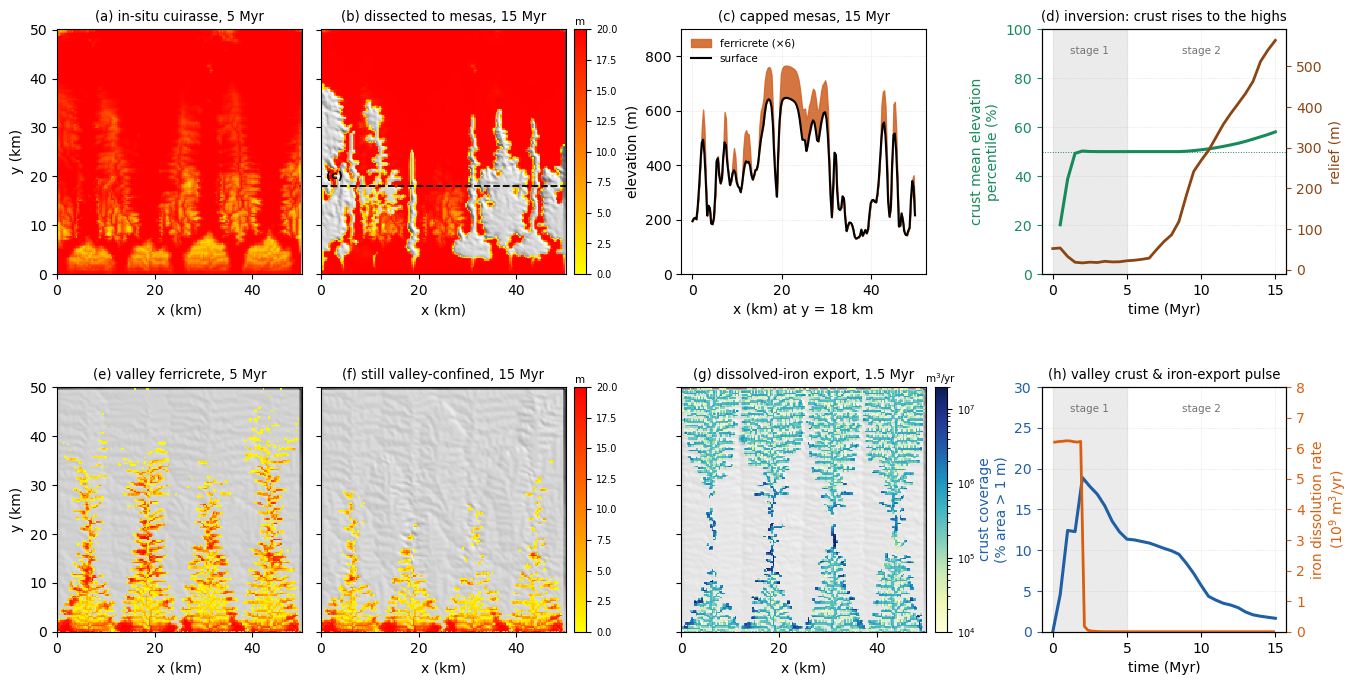

In [1]:
%matplotlib inline
import os
import numpy as np
from scipy.stats import rankdata
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource, LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from gospl.analyse.gridexport import grid_export

EX = os.getcwd()
MESH, RESO = os.path.join(EX, "inputs/gospl_mesh_valleys.npz"), 300
H5_INV = os.path.join(EX, "sim_ferricrete/h5")                       # gate OFF (cuirasse)
H5_VAL = os.path.join(EX, "../valley_ferricrete/sim_valley_ferricrete/h5")  # gate ON (valley)
DT_OUT, STAGE1_MYR = 0.25, 5.0
DMAX = 20.0                                                          # duricrust colour ceiling (m)


def gx(h5, step):
    return grid_export(h5, MESH, step, spacing=RESO)


def fld(gg, k):
    return np.array(gg[k], float)


# --- geometry (shared mesh) -------------------------------------------------
g0 = gx(H5_INV, 0)
xe = np.asarray(g0["x"]); ye = np.asarray(g0["y"]); x, y = xe / 1e3, ye / 1e3
extent = [x.min(), x.max(), y.min(), y.max()]
lam = 12.5e3
X, Y = np.meshgrid(xe, ye)
rc = 0.5 + 0.5 * np.cos(2.0 * np.pi * X / lam)                       # 1 on the rises, 0 in the valleys
inl = Y > 15e3                                                       # inland of the outlet plain
z0 = fld(g0, "elev")
valley = (rc < 0.15) & inl & np.isfinite(z0)                        # initial valley floors
rise = (rc > 0.85) & inl & np.isfinite(z0)                          # initial rises
ls = LightSource(azdeg=315, altdeg=45)


def hillshade(ax, z):
    hs = ls.hillshade(np.nan_to_num(z, nan=np.nanmin(z)), vert_exag=3.0,
                      dx=xe[1] - xe[0], dy=ye[1] - ye[0])
    ax.imshow(hs, cmap="gray", extent=extent, origin="lower", vmin=0, vmax=1,
              alpha=0.85, aspect="auto")


def inset_cbar(fig, ax, im, unit):
    """Slim colour bar just outside the right edge (does NOT shrink the square box).
    The unit sits as a compact label ABOVE the bar so nothing extends rightward into
    the neighbouring panel (the field name is already in the panel title)."""
    cax = ax.inset_axes([1.035, 0.0, 0.05, 1.0])
    cb = fig.colorbar(im, cax=cax)
    cb.ax.tick_params(labelsize=7)
    cax.set_title(unit, fontsize=7.5, pad=3)
    return cb


def duri_map(ax, h5, tM, title, ylab=False):
    g = gx(h5, int(round(tM / DT_OUT)))
    z, d = fld(g, "elev"), fld(g, "duricrust")
    ax.set_box_aspect(1.0); ax.set_xlabel("x (km)")
    if ylab:
        ax.set_ylabel("y (km)")
    else:
        ax.tick_params(labelleft=False)
    hillshade(ax, z)
    im = ax.imshow(np.where(d > 0.3, d, np.nan), cmap="autumn_r", extent=extent,
                   origin="lower", vmin=0, vmax=DMAX, interpolation="nearest", aspect="auto")
    ax.set_title(title, fontsize=9.5)
    return im, z, d


# --- time series (both runs) ------------------------------------------------
steps = list(range(0, int(round(15.0 / DT_OUT)) + 1, 2))
t = np.array(steps) * DT_OUT
vol_i, cpct_i, relief_i = [], [], []           # in-situ: crust vol, elevation rank, relief
cov_v = []                                      # valley: crust coverage
for s in steps:
    gi = gx(H5_INV, s); di = fld(gi, "duricrust"); zi = fld(gi, "elev")
    mi = inl & np.isfinite(zi)
    vol_i.append(np.nansum(di[mi]))
    relief_i.append(np.nanmax(zi[mi]) - np.nanmin(zi[mi]))
    cc = (di > 0.5) & mi
    if cc.sum() > 5:
        pr = np.full(zi.shape, np.nan); pr[mi] = rankdata(zi[mi]) / mi.sum() * 100
        cpct_i.append(np.nanmean(pr[cc]))
    else:
        cpct_i.append(np.nan)

    gv = gx(H5_VAL, s); dv = fld(gv, "duricrust"); zv = fld(gv, "elev")
    mv = inl & np.isfinite(zv)
    cov_v.append(100.0 * np.mean(dv[mv] > 1.0))
vol_i, cpct_i, relief_i, cov_v = map(np.array, (vol_i, cpct_i, relief_i, cov_v))

# Dissolved-iron pulse from the conserved solute budget (m3-equiv/yr): the per-interval
# dissolution rate = d(cumulative dissolved)/dt, which collapses as the finite source
# pool empties (the wet-phase pulse).
bud = np.genfromtxt(os.path.join(EX, "../valley_ferricrete/sim_valley_ferricrete/gw_solute_budget.csv"),
                    delimiter=",", names=True)
diss_rate = np.diff(bud["dissolved_iron"]) / np.diff(bud["time"])
t_rate = 0.5 * (bud["time"][1:] + bud["time"][:-1]) / 1e6


def stage_shade(ax):
    ax.axvspan(0, STAGE1_MYR, color="0.92", zorder=0)
    yl = ax.get_ylim(); yt = yl[1] - 0.07 * (yl[1] - yl[0])        # labels at the TOP
    ax.text(STAGE1_MYR / 2, yt, "stage 1", ha="center", va="top", fontsize=7.5, color="0.45")
    ax.text((STAGE1_MYR + 15) / 2, yt, "stage 2", ha="center", va="top", fontsize=7.5, color="0.45")


def line_panel(cell):
    ax = fig.add_subplot(cell); ax.set_box_aspect(1.0)             # square, matches the maps
    return ax


# ============================ figure ========================================
# Manual placement so the map pairs sit CLOSE together (small gap) while the gap to a
# line-plot / colour-bar is wider. All panels are the same square size.
figW, figH = 13.6, 7.3
fig = plt.figure(figsize=(figW, figH))
PW = 0.180                                        # panel width (fig fraction)
PH = PW * figW / figH                             # square
GT, GW = 0.014, 0.085                             # tight (map-map) and wide (map->plot) gaps
X0 = 0.05
XA = X0; XB = XA + PW + GT; XC = XB + PW + GW; XD = XC + PW + GW      # columns (a/e, b/f, c/g, d/h)
YT, YB = 0.575, 0.085                             # top / bottom row bottoms


def cell(xl, yb):
    return fig.add_axes([xl, yb, PW, PH])


# ---- TOP ROW: in-situ cuirasse -> capped mesas (gate OFF) -------------------
imA, _, _ = duri_map(cell(XA, YT), H5_INV, 5.0, "(a) in-situ cuirasse, 5 Myr", ylab=True)
axB = cell(XB, YT); imB, zB, dB = duri_map(axB, H5_INV, 15.0, "(b) dissected to mesas, 15 Myr")
inset_cbar(fig, axB, imB, "m")

# (c) cross-section at 15 Myr: pick the inland row of highest relief so the transect
# crosses BOTH capped mesas and the incised bare valleys (shows the inversion).
zrel = np.where(np.isfinite(zB), zB, np.nan)
relief_row = np.nanmax(zrel, axis=1) - np.nanmin(zrel, axis=1)
hascap = ((dB > 0.3) & np.isfinite(zB)).sum(axis=1) > 3
relief_row[(y < 18) | ~hascap] = -1                                # inland, and carries a cap
iyt = int(np.nanargmax(relief_row)); EXAG = 6
# mark the transect line on panel (b)
axB.axhline(y[iyt], color="k", lw=1.3, ls="--")
axB.text(1.0, y[iyt] + 1.0, "(c)", color="k", fontsize=8, fontweight="bold", va="bottom")
zr, dr = zB[iyt, :], dB[iyt, :]
axc = cell(XC, YT)
axc.fill_between(x, zr, zr + np.where(dr > 0.3, dr, 0.0) * EXAG, color="#d1662a", alpha=0.9, label=f"ferricrete (×{EXAG})")
axc.plot(x, zr, color="k", lw=1.5, label="surface")
axc.set_ylim(0, 900)
axc.set_xlabel(f"x (km) at y = {y[iyt]:.0f} km"); axc.set_ylabel("elevation (m)")
axc.set_title("(c) capped mesas, 15 Myr", fontsize=9.5)
axc.legend(fontsize=7.5, frameon=False, loc="upper left"); axc.grid(True, ls=":", lw=0.5, alpha=0.5)

# (d) in-situ crust through time: elevation rank (inversion) + relief
axd = cell(XD, YT)
axd.plot(t, cpct_i, "-", color="#178a5a", lw=2.2)
axd.axhline(50, color="#178a5a", lw=0.7, ls=":")
axd.set_ylabel("crust mean elevation\npercentile (%)", color="#178a5a"); axd.set_ylim(0, 100)
axd.tick_params(axis="y", colors="#178a5a"); axd.set_xlabel("time (Myr)")
axd.set_title("(d) inversion: crust rises to the highs", fontsize=9.5)
axd.grid(True, ls=":", lw=0.5, alpha=0.5)
axd2 = axd.twinx()
axd2.plot(t, relief_i, "-", color="#8B4513", lw=2.0)
axd2.set_ylabel("relief (m)", color="#8B4513"); axd2.tick_params(axis="y", colors="#8B4513")
stage_shade(axd)

# ---- BOTTOM ROW: absolute-accumulation valley ferricrete (gate ON) ---------
imE, _, _ = duri_map(cell(XA, YB), H5_VAL, 5.0, "(e) valley ferricrete, 5 Myr", ylab=True)
axF = cell(XB, YB); imF, _, _ = duri_map(axF, H5_VAL, 15.0, "(f) still valley-confined, 15 Myr")
inset_cbar(fig, axF, imF, "m")

# (g) exported dissolved iron (soluteflux) at 1.5 Myr over the drainage (aligned under c)
axg = cell(XC, YB); axg.set_box_aspect(1.0); axg.set_xlabel("x (km)"); axg.tick_params(labelleft=False)
gS = gx(H5_VAL, int(round(1.5 / DT_OUT))); zS = fld(gS, "elev"); sfS = fld(gS, "soluteflux")
hillshade(axg, zS)
img = axg.imshow(np.where(sfS > 1.0e4, sfS, np.nan), cmap="YlGnBu", extent=extent, origin="lower",
                 norm=LogNorm(vmin=1.0e4, vmax=2.0e7), interpolation="nearest", aspect="auto")
axg.set_title("(g) dissolved-iron export, 1.5 Myr", fontsize=9.5)
inset_cbar(fig, axg, img, "m$^3$/yr")

# (h) valley crust coverage + dissolved-iron export pulse through time (aligned under d)
axh = cell(XD, YB)
axh.plot(t, cov_v, "-", color="#1f5fa6", lw=2.2)
axh.set_ylabel("crust coverage\n(% area > 1 m)", color="#1f5fa6"); axh.tick_params(axis="y", colors="#1f5fa6")
axh.set_xlabel("time (Myr)"); axh.set_title("(h) valley crust & iron-export pulse", fontsize=9.5)
axh.set_ylim(0, 30.0); axh.grid(True, ls=":", lw=0.5, alpha=0.5)
axh2 = axh.twinx()
axh2.plot(t_rate, diss_rate / 1e9, "-", color="#d95f0e", lw=2.0)
axh2.set_ylabel("iron dissolution rate\n(10$^9$ m$^3$/yr)", color="#d95f0e"); axh2.tick_params(axis="y", colors="#d95f0e")
axh2.set_ylim(0, 8)
stage_shade(axh)

# fig.savefig("fig_ex_ferricrete.pdf", bbox_inches="tight")
# fig.savefig("fig_ex_ferricrete.png", dpi=150, bbox_inches="tight")
print(f"wrote fig_ex_ferricrete.pdf / .png | in-situ crust percentile {np.nanmin(cpct_i):.0f}->{cpct_i[-1]:.0f}, "
      f"relief {relief_i[0]:.0f}->{relief_i[-1]:.0f} m | valley coverage peak {np.nanmax(cov_v):.0f}%, "
      f"iron dissolution peak {np.nanmax(diss_rate)/1e9:.1f}e9 m3/yr")
plt.show()

## Solute budget

The domain-integrated budget of each dissolved species, written by goSPL at every output (`sim_ferricrete/gw_solute_budget.csv`): cumulative dissolved, precipitated into the duricrust and exported to the rivers. The last line closes the budget: dissolved = precipitated + exported.

In [2]:
import pandas as pd
bud = pd.read_csv('sim_ferricrete/gw_solute_budget.csv')
print(bud.tail(3).to_string(index=False))
last = bud.iloc[-1]
for sp in [c[len('dissolved_'):] for c in bud.columns if c.startswith('dissolved_')]:
    d, p, o = last['dissolved_' + sp], last['precipitated_' + sp], last['oceanflux_' + sp]
    print('%-10s dissolved %.4g  precipitated %.4g  exported %.4g  closure %.1e' % (sp, d, p, o, (d - p - o) / d if d else 0.0))

      time  dissolved_iron  precipitated_iron  oceanflux_iron  riverToOcean_iron
14500000.0    5.918140e+16       5.451580e+10    5.918140e+16       1184600000.0
14760000.0    5.995060e+16       5.451670e+10    5.995060e+16       1206960000.0
15000000.0    6.065900e+16       5.451760e+10    6.065900e+16       1183730000.0
iron       dissolved 6.066e+16  precipitated 5.452e+10  exported 6.066e+16  closure -9.0e-07
